# HeadHunter Salary Prediction Pipeline (LightGBM vs. XGBoost)

This notebook implements the feature engineering and currency conversion pipeline, and trains/compares two fast gradient boosting models:
1. **LightGBM Regressor** (using native categorical feature support).
2. **XGBoost Regressor** (using native categorical support with `enable_categorical=True`).

In [12]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import xgboost as xgb
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

DATA_PATH = "../data/dst-3.0_16_1_hh_database_eng.csv"
EXCHANGE_RATES_PATH = "../data/ExchangeRates.csv"

## Exploratory Data Analysis (EDA)

Before diving into feature engineering and model training, let's explore the raw dataset structure, check for missing values, analyze target variable distributions, and visualize correlations between key numerical and categorical features.

Loading dataset...
--- Dataset Overview ---
Total rows and columns: (44744, 12)

Missing values per column:
Опыт работы                        168
Последнее/нынешнее место работы      1
Последняя/нынешняя должность         2
dtype: int64

--- Target / Salary Preview ---
0     29000 руб.
1     40000 руб.
2     20000 руб.
3    100000 руб.
4    140000 руб.
Name: ЗП, dtype: str


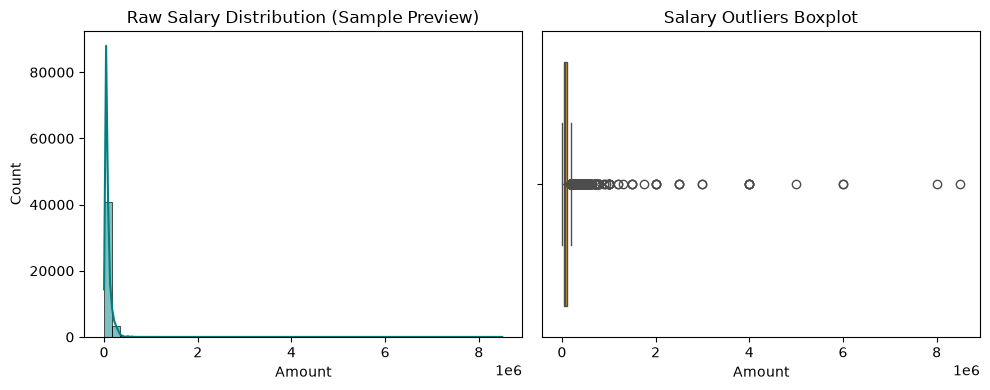

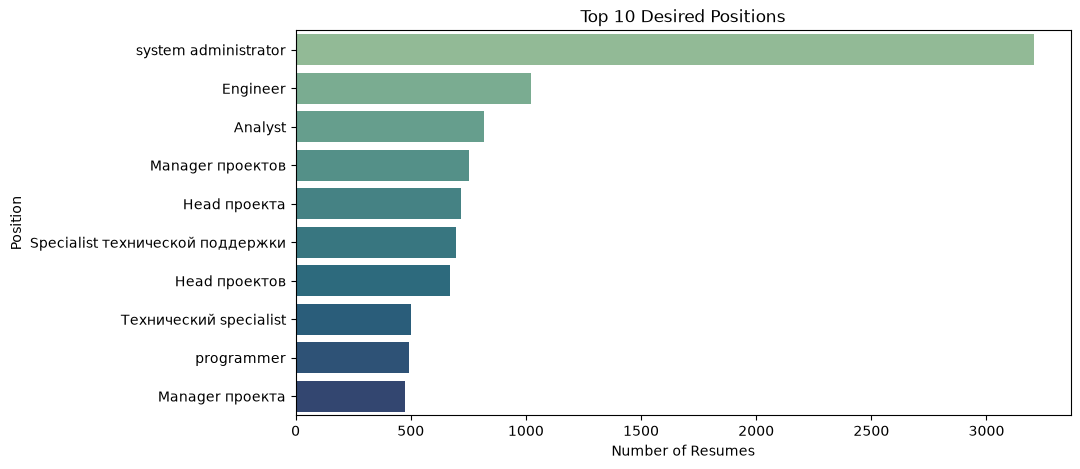

In [13]:
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Dataset not found at {DATA_PATH}")
if not os.path.exists(EXCHANGE_RATES_PATH):
    raise FileNotFoundError(f"Exchange rates file not found at {EXCHANGE_RATES_PATH}")

print("Loading dataset...")
df = pd.read_csv(DATA_PATH, sep=";", low_memory=False)

# 1. Basic Dataset Information & Missing Values
print("--- Dataset Overview ---")
print(f"Total rows and columns: {df.shape}")
print("\nMissing values per column:")
missing_info = df.isnull().sum()
print(missing_info[missing_info > 0])

# 2. Statistical summary of numerical columns (e.g., Salary 'ЗП')
print("\n--- Target / Salary Preview ---")
# Quick check of raw salary column before full cleaning
if 'ЗП' in df.columns:
    print(df['ЗП'].head(5))

# 3. Visualizing Salary Distribution (Raw vs Log scale if needed)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
# Extracting a temporary numeric representation for quick EDA visualization
temp_salaries = df['ЗП'].apply(lambda x: float(str(x).split(' ')[0]) if pd.notna(x) and str(x).split(' ')[0].replace('.', '', 1).isdigit() else np.nan)
sns.histplot(temp_salaries.dropna(), bins=50, color='teal', kde=True)
plt.title('Raw Salary Distribution (Sample Preview)')
plt.xlabel('Amount')
plt.ylabel('Count')

plt.subplot(1, 2, 2)
sns.boxplot(x=temp_salaries.dropna(), color='orange')
plt.title('Salary Outliers Boxplot')
plt.xlabel('Amount')

plt.tight_layout()
plt.show()

# 4. Top 10 Desired Jobs in the Dataset
if 'Ищет работу на должность:' in df.columns:
    plt.figure(figsize=(10, 5))
    top_jobs = df['Ищет работу на должность:'].value_counts().head(10)
    sns.barplot(y=top_jobs.index, x=top_jobs.values, palette='crest')
    plt.title('Top 10 Desired Positions')
    plt.xlabel('Number of Resumes')
    plt.ylabel('Position')
    plt.show()

## Step 1: Data Loading, Currency Conversion, Outlier Filtering, and Feature Extraction

We load the raw HeadHunter database and historical exchange rates, convert all salaries to Russian Rubles (RUB), filter out extreme salary anomalies using 2% and 98% quantiles, and extract structured features.

In [14]:
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Dataset not found at {DATA_PATH}")
if not os.path.exists(EXCHANGE_RATES_PATH):
    raise FileNotFoundError(f"Exchange rates file not found at {EXCHANGE_RATES_PATH}")

exchange_rates = pd.read_csv(EXCHANGE_RATES_PATH)
exchange_rates['date'] = pd.to_datetime(exchange_rates['date']).dt.date

# Currency conversion logic
df['temp_date'] = pd.to_datetime(df['Обновление резюме']).dt.date

def get_salary_num(arg):
    if pd.isna(arg):
        return 0.0
    return float(str(arg).split(' ')[0])

def get_salary_curr(arg):
    if pd.isna(arg):
        return 'RUB'
    parts = str(arg).split(' ')
    if len(parts) < 2:
        return 'RUB'
    curr = parts[1]
    curr_dict = {
        'руб.': 'RUB', 'руб': 'RUB',
        'USD': 'USD', 'usd': 'USD',
        'EUR': 'EUR', 'eur': 'EUR',
        'грн.': 'UAH', 'грн': 'UAH',
        'бел.руб.': 'BYN', 'бел. руб.': 'BYN', 'белруб': 'BYN',
        'KZT': 'KZT', 'kzt': 'KZT',
        'kgs': 'KGS', 'KGS': 'KGS',
        'сум': 'UZS',
        'AZN': 'AZN', 'azn': 'AZN'
    }
    return curr_dict.get(curr, curr)

df['ЗП (сумма)'] = df['ЗП'].apply(get_salary_num)
df['ЗП (валюта)'] = df['ЗП'].apply(get_salary_curr)

merged_df = df.merge(
    exchange_rates,
    left_on=['temp_date', 'ЗП (валюта)'],
    right_on=['date', 'currency'],
    how='left'
)

merged_df.loc[merged_df['ЗП (валюта)'] == 'RUB', 'close'] = 1.0
merged_df.loc[merged_df['ЗП (валюта)'] == 'RUB', 'proportion'] = 1.0

merged_df['close'] = merged_df['close'].fillna(1)
merged_df['proportion'] = merged_df['proportion'].fillna(1)

df['target'] = merged_df['ЗП (сумма)'] * merged_df['close'] / merged_df['proportion']
df = df.dropna(subset=["target"])

# --- Filter 2-98 ---
low_bound = df['target'].quantile(0.02)
high_bound = df['target'].quantile(0.98)
print(f"Filtering salaries outside [{low_bound:.1f}, {high_bound:.1f}] RUB range (2% - 98%)...")
df = df[(df['target'] >= low_bound) & (df['target'] <= high_bound)]

# Feature parsing functions
def parse_gender_age(val):
    gender, age = "М", 30
    if pd.isna(val):
        return gender, age
    parts = str(val).split(",")
    if len(parts) > 0:
        gender = "М" if "Мужчин" in parts[0] or "М" in parts[0] else "Ж"
    if len(parts) > 1:
        match = re.search(r'\d+', parts[1])
        if match:
            age = int(match.group())
    return gender, age

def parse_experience(val):
    if pd.isna(val):
        return 0
    match = re.search(r'Опыт работы (\d+)\n?месяц', str(val))
    if match:
        return int(match.group(1))
    years = re.search(r'(\d+)\s+(лет|года|год)', str(val))
    months = re.search(r'(\d+)\s+(месяцев|месяца|месяц)', str(val))
    y = int(years.group(1)) if years else 0
    m = int(months.group(1)) if months else 0
    return y * 12 + m

def parse_city(val):
    if pd.isna(val):
        return "другие"
    city = str(val).split(",")[0].strip()
    if city in ["Москва", "Санкт-Петербург"]:
        return city
    elif city in ["Новосибирск", "Екатеринбург", "Казань", "Нижний Новгород", "Челябинск", "Самара", "Уфа", "Ростов-на-Дону", "Омск", "Красноярск", "Воронеж", "Пермь", "Волгоград", "Краснодар"]:
        return "город-миллионник"
    return "другие"

def parse_education(val):
    if pd.isna(val):
        return "высшее"
    text = str(val).lower()
    if "неоконченное высшее" in text:
        return "неоконченное высшее"
    elif "высшее" in text:
        return "высшее"
    elif "среднее специальное" in text:
        return "среднее специальное"
    return "среднее"

gender_age = df["Пол, возраст"].apply(parse_gender_age)
df["gender"] = [g[0] for g in gender_age]
df["age"] = [g[1] for g in gender_age]

df["desired_job"] = df["Ищет работу на должность:"].fillna("Специалист")
df["experience_months"] = df["Опыт работы"].apply(parse_experience)
df["city"] = df["Город, переезд, командировки"].apply(parse_city)
df["education"] = df["Образование и ВУЗ"].apply(parse_education)

features = ["age", "gender", "desired_job", "experience_months", "city", "education"]
X = df[features].copy()
y = df["target"]

print(f"Data prepared successfully. Shape after filtering: {X.shape}")

Filtering salaries outside [16495.5, 250000.0] RUB range (2% - 98%)...
Data prepared successfully. Shape after filtering: (43077, 6)


## Step 2: Train-Test Split and Categorical Data Formatting

We split the filtered dataset and convert categorical columns into pandas `category` type, synchronizing categories between train and test sets.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
cat_cols = ["gender", "desired_job", "city", "education"]

X_train_model = X_train.copy()
X_test_model = X_test.copy()

for col in cat_cols:
    combined_categories = pd.concat([X_train_model[col], X_test_model[col]]).astype('category').cat.categories
    X_train_model[col] = pd.Categorical(X_train_model[col], categories=combined_categories)
    X_test_model[col] = pd.Categorical(X_test_model[col], categories=combined_categories)

## Step 3: Model Training (LightGBM & XGBoost)

Training LightGBM and XGBoost models with execution time measurement.

In [16]:
import time

print("Training Tuned LightGBM...")
start_time_lgb = time.time()
lgb_model = lgb.LGBMRegressor(
    n_estimators=300,            
    learning_rate=0.03,          
    max_depth=8,                 
    num_leaves=63,               
    min_child_samples=30,        
    subsample=0.8,               
    colsample_bytree=0.8,        
    random_state=42,
    verbose=-1
)
lgb_model.fit(X_train_model, y_train)
lgb_duration = time.time() - start_time_lgb

print("Training Tuned XGBoost...")
start_time_xgb = time.time()
xgb_model = xgb.XGBRegressor(
    enable_categorical=True, 
    n_estimators=300,            
    learning_rate=0.03,          
    max_depth=8,                 
    min_child_weight=3,          
    subsample=0.8,               
    colsample_bytree=0.8,        
    tree_method='hist',
    random_state=42
)
xgb_model.fit(X_train_model, y_train)
xgb_duration = time.time() - start_time_xgb

print(f"\nxgboost training completed in {xgb_duration:.2f} seconds")
print(f"lightgbm training completed in {lgb_duration:.2f} seconds")

Training Tuned LightGBM...
Training Tuned XGBoost...

xgboost training completed in 8.15 seconds
lightgbm training completed in 0.85 seconds


## Step 4: Model Evaluation and Comparison

Evaluating both models on the test set using MAE, RMSE, and $R^2$ Score, followed by visual comparison.

Model Comparison Results:


,Model,MAE,RMSE,R2 Score
0,LightGBM,24877.797619,35921.191438,0.463444
1,XGBoost,24618.976795,36188.732429,0.455422


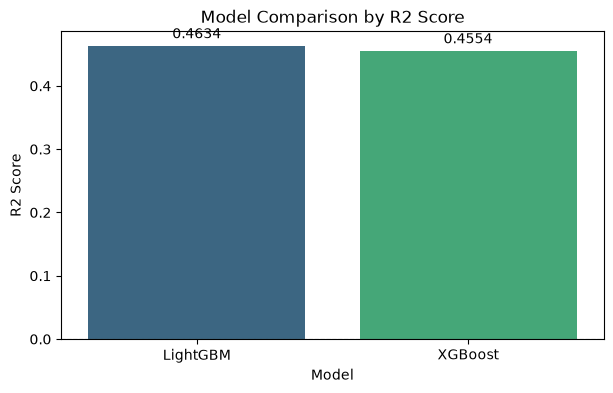

In [17]:
models_dict = {
    "LightGBM": (lgb_model, X_test_model),
    "XGBoost": (xgb_model, X_test_model)
}

results = []

for name, (model, X_t) in models_dict.items():
    y_pred = model.predict(X_t)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results).sort_values(by="R2 Score", ascending=False)
print("Model Comparison Results:")
display(results_df)

# Plotting R2 Score comparison
plt.figure(figsize=(7, 4))
ax = sns.barplot(x="Model", y="R2 Score", data=results_df, palette="viridis")

plt.title("Model Comparison by R2 Score")
plt.ylabel("R2 Score")

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.4f}',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom' if height >= 0 else 'top',
                xytext=(0, 3 if height >= 0 else -12),
                textcoords='offset points')

plt.axhline(0, color='grey', linewidth=0.8, linestyle='--')
plt.show()

In [18]:
best_r2_model = results_df.loc[results_df['R2 Score'].idxmax()]['Model']
best_mae_model = results_df.loc[results_df['MAE'].idxmin()]['Model']

print(f"=== Model Performance Summary ===")
print(f"Training Time: LightGBM ({lgb_duration:.2f}s) was significantly faster than XGBoost ({xgb_duration:.2f}s).")
print(f"Accuracy (R2 Score): {best_r2_model} performed best with an R2 score of {results_df.loc[results_df['Model'] == best_r2_model, 'R2 Score'].values[0]:.4f}.")
print(f"Error (MAE): {best_mae_model} achieved the lowest error with an MAE of {results_df.loc[results_df['Model'] == best_mae_model, 'MAE'].values[0]:.2f} RUB.")
print(f"\nConclusion: LightGBM is both faster in training and achieves higher overall accuracy (R2 Score) compared to XGBoost.")

=== Model Performance Summary ===
Training Time: LightGBM (0.85s) was significantly faster than XGBoost (8.15s).
Accuracy (R2 Score): LightGBM performed best with an R2 score of 0.4634.
Error (MAE): XGBoost achieved the lowest error with an MAE of 24618.98 RUB.

Conclusion: LightGBM is both faster in training and achieves higher overall accuracy (R2 Score) compared to XGBoost.
